In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/raesiow/fpx-off-matched/fpx_off_matched.csv
/kaggle/input/datasets/raesiow/fpx-off-matched/can_minilm.csv
/kaggle/input/datasets/raesiow/fpx-off-matched/__huggingface_repos__.json
/kaggle/input/datasets/raesiow/fpx-off-matched/cand_70.csv


In [2]:
path = '/kaggle/input/datasets/raesiow/fpx-off-matched/fpx_off_matched.csv'
df = pd.read_csv(path, dtype={"off_code": str, "fpx_code": str})

print(df.shape)                                   # expect (1884, 20)
print(df["nova"].value_counts().sort_index().tolist())  # expect [477, 61, 265, 1081]
print(df["ingredients_text"].isna().sum())        # expect 0
print(df["off_code"].is_unique)                   # expect True

(1884, 20)
[477, 61, 265, 1081]
0
True


In [3]:
df["group"] = df["off_name"].str.lower().str.strip()

print(df["group"].nunique())                 # number of distinct groups (expect somewhat fewer than 1884)
print(df["group"].value_counts().head(10))   # the biggest groups, e.g. chocolate milk, orange juice

1635
group
energy drink           8
chocolate milk         7
apple juice            7
orange juice           6
cereal                 6
ground beef            5
cottage cheese         5
lean ground beef       5
chicken noodle soup    5
peanut butter          4
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import StratifiedGroupKFold
# cut the data into 5 folds, shuffle groups before assigning so folds are not in table order
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

df["fold"] = -1 # new column , filled with -1 for now as placeholder 
for fold_num, (train_idx, test_idx) in enumerate(sgkf.split(df, df["nova"], groups=df["group"])):
    df.loc[test_idx, "fold"] = fold_num

print(pd.crosstab(df["fold"], df["nova"]))
# expect: 5 rows (folds 0-4), each with roughly 95 / 12 / 53 / 216 in the NOVA 1/2/3/4 columns
print(df.groupby("group")["fold"].nunique().max())
# expect 1  (no group appears in more than one fold)

nova    1   2   3    4
fold                  
0     108  13  53  202
1      95  11  58  214
2     101  12  46  231
3      82  13  56  209
4      91  12  52  225
1


In [5]:
df.to_csv("/kaggle/working/fpx_off_folds.csv", index=False)   # save the whole table, now with group + fold columns; index=False skips the row-number column

check = pd.read_csv("/kaggle/working/fpx_off_folds.csv", dtype={"off_code": str, "fpx_code": str})   # read it back to make sure the save worked
print(check.shape)                                     # expect (1884, 22)  (20 original + group + fold)
print(check["fold"].value_counts().sort_index().tolist())   # rows per fold; should match the crosstab row totals (376, 378, 390, 360, 380)

(1884, 22)
[376, 378, 390, 360, 380]


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer   # the tool that turns text into TF-IDF numbers

train = df[df["fold"] != 0]   # training rows: everything NOT in fold 0 (4 folds, ~1500 rows)
test  = df[df["fold"] == 0]   # test rows: fold 0 only (376 rows)

vec = TfidfVectorizer(ngram_range=(1, 2),   # use single words ("palm") AND word pairs ("palm oil")
                      min_df=2)             # ignore words that appear in fewer than 2 training texts (typos, rare noise)

X_train = vec.fit_transform(train["ingredients_text"])   # LEARN the vocabulary + IDF weights from training text, then convert it
X_test  = vec.transform(test["ingredients_text"])        # convert test text using the SAME vocabulary (no learning from test)

print(X_train.shape)   # (training rows, number of word/pair columns); expect ~1500 rows and a few thousand columns
print(X_test.shape)    # same number of columns as X_train; expect 376 rows
print(vec.get_feature_names_out()[:20])   # peek at the first 20 columns (alphabetical, so the first ones may be numbers/odd tokens)

(1508, 5822)
(376, 5822)
['000' '03' '0800' '0g' '0g dv' '0r' '10' '10 water' '100' '100 orange'
 '100 organic' '100 pure' '100 whole' '100g' '100g of' '100g per' '10g'
 '11' '12' '12 acidophilus']


In [7]:
from sklearn.linear_model import LogisticRegression          # the classifier
from sklearn.metrics import f1_score, classification_report  # tools to score the predictions

clf = LogisticRegression(class_weight="balanced",   # count mistakes on rare classes (NOVA 2) more heavily, so they aren't ignored
                         max_iter=2000)             # allow more training steps so it finishes (avoids a "did not converge" warning)

clf.fit(X_train, train["nova"])   # LEARN the word weights from training rows and their NOVA labels

pred = clf.predict(X_test)        # predict a NOVA class for each test row

print(f1_score(test["nova"], pred, average="macro"))   # macro-F1: F1 for each class, then a plain average (each class counts equally)
print(classification_report(test["nova"], pred))      # precision, recall and F1 for each NOVA class separately

0.667177624090173
              precision    recall  f1-score   support

           1       0.70      0.76      0.73       108
           2       0.50      0.62      0.55        13
           3       0.51      0.55      0.53        53
           4       0.90      0.83      0.86       202

    accuracy                           0.76       376
   macro avg       0.65      0.69      0.67       376
weighted avg       0.77      0.76      0.77       376



In [8]:
scores = []                                        # will hold one macro-F1 per fold
df["pred_tfidf"] = 0                               # new column for each row's prediction (filled in when its fold is the test fold)

for k in range(5):                                 # k = 0, 1, 2, 3, 4: each fold takes a turn as the test set
    train = df[df["fold"] != k]                    # the other 4 folds
    test  = df[df["fold"] == k]                    # this fold

    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)          # fresh vectoriser each time (no memory of earlier folds)
    X_train = vec.fit_transform(train["ingredients_text"])       # learn vocabulary from THIS fold's training rows only
    X_test  = vec.transform(test["ingredients_text"])            # convert test rows with that vocabulary

    clf = LogisticRegression(class_weight="balanced", max_iter=2000)   # fresh model each time
    clf.fit(X_train, train["nova"])                                     # train
    pred = clf.predict(X_test)                                          # predict

    df.loc[test.index, "pred_tfidf"] = pred        # store predictions in the right rows of df
    f1 = f1_score(test["nova"], pred, average="macro")   # macro-F1 for this fold
    scores.append(f1)                              # add it to the list
    print(f"fold {k}: macro-F1 = {f1:.3f}")        # print it, rounded to 3 decimals

print(f"mean = {np.mean(scores):.3f} ± {np.std(scores):.3f}")   # the headline number for the report
# expect: fold 0 = 0.667 again (same split, same settings); the others somewhere around 0.6-0.7

fold 0: macro-F1 = 0.667
fold 1: macro-F1 = 0.597
fold 2: macro-F1 = 0.676
fold 3: macro-F1 = 0.600
fold 4: macro-F1 = 0.650
mean = 0.638 ± 0.033


              precision    recall  f1-score   support

           1       0.69      0.74      0.71       477
           2       0.41      0.46      0.43        61
           3       0.51      0.60      0.55       265
           4       0.90      0.83      0.87      1081

    accuracy                           0.76      1884
   macro avg       0.63      0.66      0.64      1884
weighted avg       0.78      0.76      0.77      1884



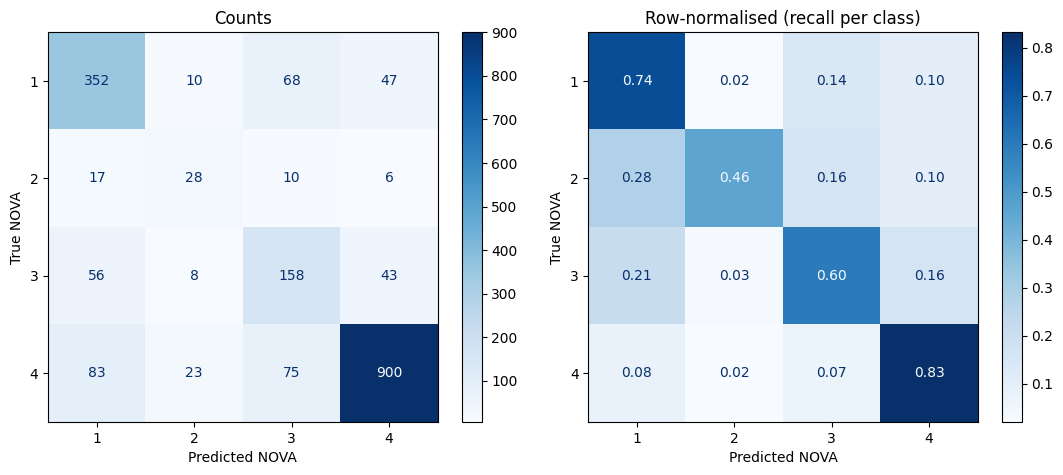

In [9]:
import matplotlib.pyplot as plt                       # plotting library
from sklearn.metrics import ConfusionMatrixDisplay    # draws a confusion matrix from labels + predictions

print(classification_report(df["nova"], df["pred_tfidf"]))   # per-class scores using every row (each row was tested once)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))     # one figure with 2 side-by-side panels

ConfusionMatrixDisplay.from_predictions(df["nova"], df["pred_tfidf"],   # true labels, predicted labels
                                        ax=axes[0],                     # draw in the left panel
                                        cmap="Blues")                   # colour scheme
axes[0].set_title("Counts")                            # left: raw numbers of rows

ConfusionMatrixDisplay.from_predictions(df["nova"], df["pred_tfidf"],
                                        ax=axes[1],
                                        cmap="Blues",
                                        normalize="true",               # divide each row by its total, so each row adds to 1
                                        values_format=".2f")            # show 2 decimals
axes[1].set_title("Row-normalised (recall per class)")   # right: share of each true class

for ax in axes:                                        # for both panels:
    ax.set_xlabel("Predicted NOVA")                    #   label the x axis
    ax.set_ylabel("True NOVA")                         #   label the y axis

plt.tight_layout()                                     # stop titles/labels overlapping
plt.savefig("/kaggle/working/cm_tfidf.png", dpi=200)   # save as an image for the report
plt.show()                                             # display it in the notebook

In [10]:
pd.set_option("display.max_colwidth", 80)   # show up to 80 characters per cell instead of cutting text short

errs = df[(df["nova"] == 4) & (df["pred_tfidf"] == 1)]   # rows that are truly NOVA 4 but predicted NOVA 1
print(len(errs))                                          # expect 83

print(errs[["fpx_name", "off_name", "source", "ingredients_text"]]   # the FoodProX food, the matched OFF product, how it was matched, and its text
      .sample(15, random_state=1))                                   # 15 random examples (random_state makes it repeatable)

83
                                                                    fpx_name  \
221                           organic flax plus pumpkin granola natures path   
1682                   fast foods fish sandwich with tartar sauce and cheese   
1151                                           carbonated citrus juice drink   
1306                                    beverages acai berry drink fortified   
984                                  apple juice beverage 40-50% juice light   
1553                                      frozen novelties juice type orange   
1410                                 beverages tropical punch ready-to-drink   
1878  tea made from powdered instant presweetened with low calorie sweetener   
1536           applesauce stewed apples sweetened with low calorie sweetener   
1117                     cereals ready-to-eat post shredded wheat spoon-size   
1723                             iced coffee pre-lightened and pre-sweetened   
1561                          cereals

In [11]:
print(df["source"].value_counts(normalize=True).round(2))     # share of each source in ALL 1,884 rows
print(errs["source"].value_counts(normalize=True).round(2))   # share of each source among the 83 4->1 errors

df["correct"] = df["nova"] == df["pred_tfidf"]                 # True if this row was predicted correctly
print(df.groupby("source")["correct"].mean().round(3))         # accuracy for each source
# if mini_only accuracy is clearly lower, that supports the planned "drop mini_only" experiment

source
both         0.55
mini_only    0.38
rf_only      0.08
Name: proportion, dtype: float64
source
both         0.51
mini_only    0.48
rf_only      0.01
Name: proportion, dtype: float64
source
both         0.776
mini_only    0.737
rf_only      0.804
Name: correct, dtype: float64


In [12]:
from sklearn.preprocessing import StandardScaler   # rescales each nutrient to mean 0, std 1
from scipy.sparse import hstack, csr_matrix        # hstack = glue matrices side by side; csr_matrix = sparse format TF-IDF uses

nut_cols = ["protein_g_f", "fat_g_f", "carb_excl_fiber_g_f", "sugars_g_f",
            "fiber_g_f", "sat_fat_g_f", "sodium_g_f"]   # the 7 FoodProX nutrients (grams per 100 g)

def run_cv(mode, train_mask=None):                                   # mode = "text", "nutrients" or "both"
    scores = []                                     # one macro-F1 per fold
    preds = pd.Series(0, index=df.index)            # one prediction per row, filled in fold by fold
    for k in range(5):                              # each fold takes a turn as test
        train = df[df["fold"] != k] # 4 training folds
        if train_mask is not None:                  # NEW: if a mask was given...
            train = train[train_mask[train.index]] 
        test  = df[df["fold"] == k]                 # 1 test fold
        parts_train, parts_test = [], []            # the input blocks we'll glue together

        if mode in ("text", "both"):                # add the TF-IDF block
            vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
            parts_train.append(vec.fit_transform(train["ingredients_text"]))   # fit on train only
            parts_test.append(vec.transform(test["ingredients_text"]))

        if mode in ("nutrients", "both"):           # add the nutrient block
            scaler = StandardScaler()
            nut_train = np.log1p(train[nut_cols])   # log(1 + grams): squashes big values so carbs (0-100) don't swamp sodium (0-2)
            nut_test  = np.log1p(test[nut_cols])
            parts_train.append(csr_matrix(scaler.fit_transform(nut_train)))   # learn mean/std from train only, then rescale
            parts_test.append(csr_matrix(scaler.transform(nut_test)))         # rescale test with the TRAIN mean/std

        X_train = hstack(parts_train).tocsr()       # glue the blocks side by side (5822 text cols + 7 nutrient cols)
        X_test  = hstack(parts_test).tocsr()

        clf = LogisticRegression(class_weight="balanced", max_iter=2000)
        clf.fit(X_train, train["nova"])             # train
        pred = clf.predict(X_test)                  # predict
        preds[test.index] = pred                    # store
        scores.append(f1_score(test["nova"], pred, average="macro"))

    print(f"{mode:10s} macro-F1 = {np.mean(scores):.3f} ± {np.std(scores):.3f}")   # one summary line per mode
    return preds                                    # hand back predictions for confusion matrices later

pred_text = run_cv("text")        # expect 0.638 ± 0.033 again (same as Cell 8, a check that the function is right)
pred_nut  = run_cv("nutrients")
pred_both = run_cv("both")

text       macro-F1 = 0.638 ± 0.033
nutrients  macro-F1 = 0.522 ± 0.017
both       macro-F1 = 0.700 ± 0.037


In [13]:
mini = df["source"] == "mini_only"                  # True for rows matched only by MiniLM

masks = {
    "all rows":        pd.Series(True, index=df.index),        # current setup
    "mini cos >= 0.65": ~mini | (df["cos"] >= 0.65),           # keep non-mini rows, plus mini rows with cos >= 0.65
    "mini cos >= 0.70": ~mini | (df["cos"] >= 0.70),
    "no mini_only":     ~mini,                                 # drop all mini_only rows
}

for name, m in masks.items():                       # run each version
    print(name, "| training rows:", m.sum())        # how many rows each version keeps
    run_cv("text", train_mask=m)                    # test set is always all rows of the fold, so scores are comparable

all rows | training rows: 1884
text       macro-F1 = 0.638 ± 0.033
mini cos >= 0.65 | training rows: 1709
text       macro-F1 = 0.634 ± 0.029
mini cos >= 0.70 | training rows: 1509
text       macro-F1 = 0.624 ± 0.016
no mini_only | training rows: 1173
text       macro-F1 = 0.614 ± 0.016


              precision    recall  f1-score   support

           1       0.71      0.83      0.76       477
           2       0.52      0.75      0.61        61
           3       0.55      0.60      0.57       265
           4       0.92      0.81      0.86      1081

    accuracy                           0.78      1884
   macro avg       0.68      0.75      0.70      1884
weighted avg       0.80      0.78      0.79      1884



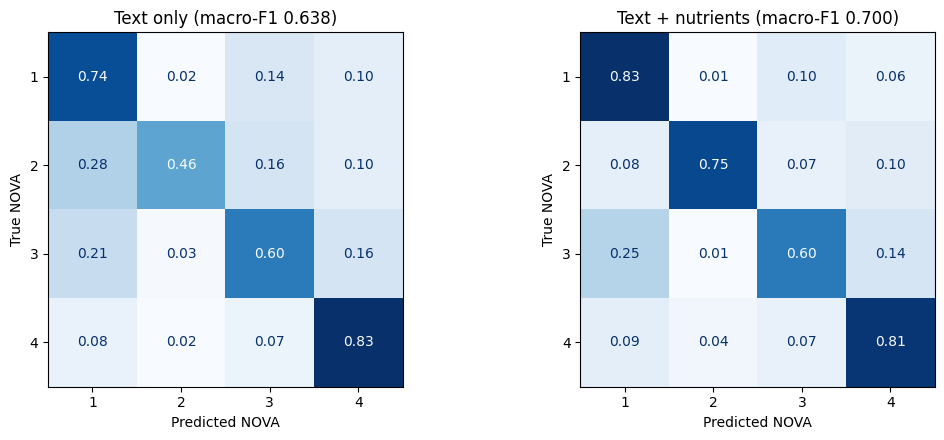

In [14]:
print(classification_report(df["nova"], pred_both))   # per-class scores for the text + nutrients model (all 1,884 rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))     # 2 panels side by side

for ax, preds, title in [(axes[0], pred_text, "Text only (macro-F1 0.638)"),          # left panel: text-only predictions
                         (axes[1], pred_both, "Text + nutrients (macro-F1 0.700)")]:  # right panel: text + nutrients predictions
    ConfusionMatrixDisplay.from_predictions(df["nova"], preds,     # true labels vs this model's predictions
                                            ax=ax,                 # draw in this panel
                                            cmap="Blues",
                                            normalize="true",      # each row adds to 1 (recall per class)
                                            values_format=".2f",   # 2 decimals
                                            colorbar=False)        # skip the colour bar so the panels stay the same size
    ax.set_title(title)                                            # panel title
    ax.set_xlabel("Predicted NOVA")
    ax.set_ylabel("True NOVA")

plt.tight_layout()                                         # stop labels overlapping
plt.savefig("/kaggle/working/cm_text_vs_both.png", dpi=200)   # save for the report
plt.show()

In [15]:
out = df[["fpx_code", "off_code", "nova", "fold"]].copy()   # IDs, true label and fold, to line rows up later
out["pred_text"] = pred_text                                # text-only TF-IDF predictions
out["pred_both"] = pred_both                                # text + nutrients predictions
out.to_csv("/kaggle/working/baseline_preds.csv", index=False)   # save the file
print(out.shape)                                            # expect (1884, 6)

(1884, 6)
